# 00 · Data Audit (Phase P0)

**Goal:** before building anything, find out what public data actually exists for each sector group
and country, how far back it goes, and how much work it takes to collect.

**Go / no-go rule (from RESEARCH_DESIGN.md §10):** a sector group passes if at least one outcome
measure covers **≥ 6 countries × ≥ 8 years**. If it doesn't, that group's scope is narrowed, or the
gap is filled from a UCL-licensed source.

| Section | What it checks |
|---|---|
| 1 | Source registry: every source in the design, with type and status |
| 2 | Drivers: World Bank / Findex coverage |
| 3 | Fintech outcome: IMF Financial Access Survey coverage |
| 4 | Fintech outcome: central-bank payment statistics (reachability; manual collection) |
| 5 | Digital-sector outcome: e-Conomy SEA reports and country reports |
| 6 | Crypto outcome: CoinGecko, regulators, adoption indices |
| 7 | Other drivers: COVID restrictions, news attention (GDELT) |
| 8 | Go / no-go verdict per sector group |

## Setup

In [1]:
import sys, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import (COUNTRIES, TIER_A, TIER_B, NAME, ORIGINS, SECTORS, WB_INDICATORS,
                            IMF_FAS_INDICATORS, RAW, PROC, FIG)
from drivers import fetch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)

SEA = list(COUNTRIES)
MIN_COUNTRIES, MIN_YEARS = 6, 8

def coverage(df, value_col="value", nonzero=True):
    """Years with usable data per (country, indicator). 'Usable' = not missing and, by default, non-zero."""
    d = df.dropna(subset=[value_col])
    if nonzero:
        d = d[d[value_col] != 0]
    return d.groupby(["indicator", "iso3"]).year.agg(n_years="nunique", first="min", last="max").reset_index()

def passes(cov, indicator):
    c = cov[(cov.indicator == indicator) & (cov.iso3.isin(SEA))]
    return int((c.n_years >= MIN_YEARS).sum())

## 1 · Source registry
Every source named in the design, how it is collected, and which question it serves. `auto` sources have
a cached fetcher in `drivers/fetch.py`. `manual` sources need hand collection (PDF tables, country
statistics pages). `licensed` sources are UCL databases, used only after a licence check.

In [2]:
registry = pd.DataFrame([
    # name, role, sector_group, collection, url
    ("World Bank WDI + Findex", "drivers", "all", "auto", "https://api.worldbank.org/v2/"),
    ("IMF Financial Access Survey", "outcome", "fintech", "auto", "https://api.imf.org/external/sdmx/2.1/"),
    ("e-Conomy SEA regional reports (2021-25)", "outcome", "digital", "auto (PDF) + manual transcription", "https://services.google.com/fh/files/misc/"),
    ("e-Conomy SEA country reports", "outcome", "digital", "manual transcription", "https://services.google.com/fh/files/misc/"),
    ("Bank Indonesia payment statistics (SPIP, QRIS)", "outcome", "fintech", "manual", "https://www.bi.go.id/id/statistik/ekonomi-keuangan/spip/default.aspx"),
    ("Bank Negara Malaysia payment statistics", "outcome", "fintech", "manual", "https://www.bnm.gov.my/payment-statistics"),
    ("Bank of Thailand payment statistics", "outcome", "fintech", "manual / API key", "https://www.bot.or.th/en/statistics.html"),
    ("Bangko Sentral ng Pilipinas statistics", "outcome", "fintech", "manual", "https://www.bsp.gov.ph/SitePages/Statistics/Statistics.aspx"),
    ("Monetary Authority of Singapore statistics", "outcome", "fintech", "manual", "https://www.mas.gov.sg/statistics"),
    ("State Bank of Vietnam", "outcome", "fintech", "manual", "https://www.sbv.gov.vn"),
    ("National Bank of Cambodia", "outcome", "fintech", "manual", "https://www.nbc.gov.kh"),
    ("Bank of the Lao PDR", "outcome", "fintech", "manual", "https://www.bol.gov.la"),
    ("Central Bank of Myanmar", "outcome", "fintech", "manual", "https://www.cbm.gov.mm"),
    ("Brunei Darussalam Central Bank", "outcome", "fintech", "manual", "https://www.bdcb.gov.bn"),
    ("Banco Central de Timor-Leste", "outcome", "fintech", "manual", "https://www.bancocentral.tl"),
    ("CoinGecko API (exchanges)", "outcome", "crypto", "auto", "https://api.coingecko.com/api/v3/exchanges"),
    ("Chainalysis Global Crypto Adoption Index", "outcome", "crypto", "manual (annual report)", "https://www.chainalysis.com/blog/"),
    ("Electric Capital Developer Report", "outcome", "crypto", "manual", "https://www.developerreport.com"),
    ("Indonesia Bappebti (crypto transactions)", "outcome", "crypto", "manual", "https://bappebti.go.id"),
    ("Indonesia OJK (crypto, from 2025)", "outcome", "crypto", "manual", "https://www.ojk.go.id"),
    ("Thailand SEC (digital assets)", "outcome", "crypto", "manual", "https://www.sec.or.th"),
    ("Securities Commission Malaysia (DAX register)", "event dates", "crypto", "manual", "https://www.sc.com.my"),
    ("Oxford COVID-19 Government Response Tracker", "drivers", "all", "auto", "https://github.com/OxCGRT/covid-policy-dataset"),
    ("GDELT DOC 2.0 (news volume)", "drivers / hype control", "all", "auto (paced)", "https://api.gdeltproject.org/api/v2/doc/doc"),
    ("Google Trends", "drivers / hype control", "all", "auto (heavily rate-limited)", "https://trends.google.com"),
], columns=["source", "role", "sector_group", "collection", "url"])

manual = registry.collection.str.contains("manual")
status = {u: fetch.http_status(u) for u in registry.loc[manual, "url"].unique()}
registry["http_status"] = registry.url.map(lambda u: status.get(u, (None, ""))[0])
registry["content_type"] = registry.url.map(lambda u: status.get(u, (None, ""))[1])
registry.to_csv(PROC / "source_registry.csv", index=False)
registry

,source,role,sector_group,collection,url,http_status,content_type
0,World Bank WDI + Findex,drivers,all,auto,https://api.worldbank.org/v2/,NaN,
1,IMF Financial Access Survey,outcome,fintech,auto,https://api.imf.org/external/sdmx/2.1/,NaN,
2,e-Conomy SEA regional reports (2021-25),outcome,digital,auto (PDF) + manual transcription,https://services.google.com/fh/files/misc/,404.0,text/html
3,e-Conomy SEA country reports,outcome,digital,manual transcription,https://services.google.com/fh/files/misc/,404.0,text/html
4,"Bank Indonesia payment statistics (SPIP, QRIS)",outcome,fintech,manual,https://www.bi.go.id/id/statistik/ekonomi-keua...,200.0,text/html
5,Bank Negara Malaysia payment statistics,outcome,fintech,manual,https://www.bnm.gov.my/payment-statistics,403.0,text/html
6,Bank of Thailand payment statistics,outcome,fintech,manual / API key,https://www.bot.or.th/en/statistics.html,200.0,text/html
7,Bangko Sentral ng Pilipinas statistics,outcome,fintech,manual,https://www.bsp.gov.ph/SitePages/Statistics/St...,403.0,text/html
8,Monetary Authority of Singapore statistics,outcome,fintech,manual,https://www.mas.gov.sg/statistics,200.0,text/html
9,State Bank of Vietnam,outcome,fintech,manual,https://www.sbv.gov.vn,200.0,text/html


Landing pages that fail here (non-200) may only be blocking automated requests. They are flagged for
a manual browser check, not dropped.

## 2 · Drivers: World Bank / Findex

In [3]:
wb = fetch.fetch_worldbank()
wb_cov = coverage(wb, nonzero=False)
wb_tab = wb_cov[wb_cov.iso3.isin(SEA)].pivot(index="iso3", columns="indicator", values="n_years").reindex(SEA)
wb_tab.index = [f"{NAME[c]} ({COUNTRIES[c][2]})" for c in wb_tab.index]
print("Years of data per country (2000-2025). Findex 'account_ownership_pct' is a survey every ~3 years.")
wb_tab

Years of data per country (2000-2025). Findex 'account_ownership_pct' is a survey every ~3 years.


indicator,account_ownership_pct,children_0_14_pct,electricity_access_pct,gdp_pc_ppp,internet_users_pct,mobile_subs_per100,population,private_credit_pct_gdp,remittance_inflows_pct_gdp,remittance_inflows_usd,urban_pct,working_age_pct
Indonesia (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,17.0,26.0,26.0,26.0,26.0
Malaysia (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,26.0,25.0,25.0,26.0,26.0
Philippines (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,26.0,26.0,26.0,26.0,26.0
Singapore (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,21.0,NaN,NaN,26.0,26.0
Thailand (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,19.0,26.0,26.0,26.0,26.0
Vietnam (A),5.0,26.0,25.0,26.0,25.0,25.0,26.0,23.0,5.0,5.0,26.0,26.0
Brunei (B),NaN,26.0,25.0,26.0,25.0,25.0,26.0,20.0,NaN,NaN,26.0,26.0
Cambodia (B),5.0,26.0,25.0,26.0,25.0,25.0,26.0,26.0,26.0,26.0,26.0,26.0
Laos (B),4.0,26.0,25.0,26.0,25.0,24.0,26.0,11.0,25.0,25.0,26.0,26.0
Myanmar (B),3.0,26.0,25.0,26.0,20.0,25.0,26.0,21.0,20.0,20.0,26.0,26.0


## 3 · Fintech outcome: IMF Financial Access Survey
The FAS is the only **harmonised** cross-country source for digital-payment activity. Coverage below
counts only **non-zero** years. A country without mobile money (e.g. Singapore) reports zeros, which
means "not applicable" rather than "no boom".

In [4]:
fas = fetch.fetch_imf_fas()
fas_cov = coverage(fas)
fas_tab = fas_cov[fas_cov.iso3.isin(SEA)].pivot(index="iso3", columns="indicator", values="n_years").reindex(SEA)
fas_rng = fas_cov[fas_cov.iso3.isin(SEA)].assign(r=lambda d: d["first"].astype(str) + "–" + d["last"].astype(str)) \
            .pivot(index="iso3", columns="indicator", values="r").reindex(SEA)
fas_tab.index = fas_rng.index = [f"{NAME[c]} ({COUNTRIES[c][2]})" for c in fas_tab.index]
print("Non-zero years per country:")
display(fas_tab.fillna(0).astype(int))
print("Year range:")
fas_rng.fillna("–")

Non-zero years per country:


indicator,mobile_internet_banking_tx_per_1000_adults,mobile_internet_banking_tx_value_pct_gdp,mobile_money_accounts_per_1000_adults,mobile_money_balances_pct_gdp,mobile_money_tx_per_1000_adults,mobile_money_tx_value_pct_gdp
Indonesia (A),13,13,19,14,19,19
Malaysia (A),13,13,7,7,7,7
Philippines (A),7,7,15,10,15,15
Singapore (A),0,0,0,0,0,0
Thailand (A),16,16,11,11,11,11
Vietnam (A),11,11,4,0,2,2
Brunei (B),0,0,0,0,0,0
Cambodia (B),3,3,17,7,17,17
Laos (B),0,0,0,0,0,0
Myanmar (B),3,3,7,7,7,7


Year range:


indicator,mobile_internet_banking_tx_per_1000_adults,mobile_internet_banking_tx_value_pct_gdp,mobile_money_accounts_per_1000_adults,mobile_money_balances_pct_gdp,mobile_money_tx_per_1000_adults,mobile_money_tx_value_pct_gdp
Indonesia (A),2013–2025,2013–2025,2007–2025,2012–2025,2007–2025,2007–2025
Malaysia (A),2013–2025,2013–2025,2008–2014,2008–2014,2008–2014,2008–2014
Philippines (A),2018–2024,2018–2024,2010–2024,2010–2019,2010–2024,2010–2024
Singapore (A),–,–,–,–,–,–
Thailand (A),2010–2025,2010–2025,2015–2025,2015–2025,2015–2025,2015–2025
Vietnam (A),2015–2025,2015–2025,2022–2025,–,2024–2025,2024–2025
Brunei (B),–,–,–,–,–,–
Cambodia (B),2023–2025,2023–2025,2009–2025,2009–2015,2009–2025,2009–2025
Laos (B),–,–,–,–,–,–
Myanmar (B),2018–2020,2018–2020,2014–2020,2014–2020,2014–2020,2014–2020


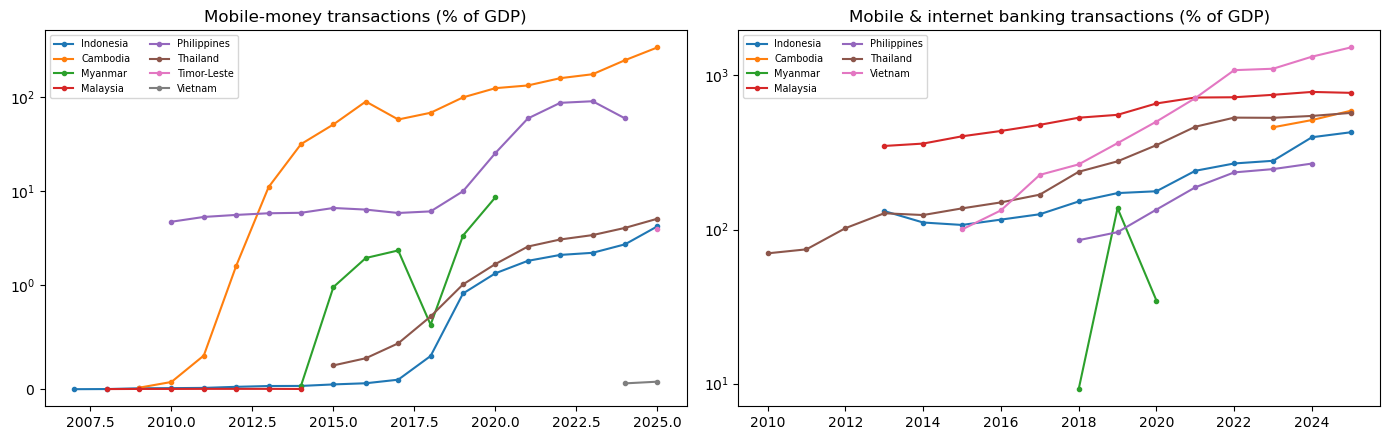

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for ax, ind, title in [(axes[0], "mobile_money_tx_value_pct_gdp", "Mobile-money transactions (% of GDP)"),
                       (axes[1], "mobile_internet_banking_tx_value_pct_gdp", "Mobile & internet banking transactions (% of GDP)")]:
    d = fas[(fas.indicator == ind) & (fas.iso3.isin(SEA))]
    for c, g in d.groupby("iso3"):
        g = g.sort_values("year")
        if g.value.max() > 0:
            ax.plot(g.year, g.value, marker="o", ms=3, lw=1.5, label=NAME[c])
    ax.set_title(title); ax.set_yscale("symlog", linthresh=1); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "00_imf_fas_preview.png", dpi=150); plt.show()

## 4 · Fintech outcome: central-bank payment statistics
Every central bank publishes payment data, but in its own format (Excel, PDF annual reports,
dashboards). None of these can be fetched with one shared API. Reachability from section 1:

In [6]:
registry[registry.source.str.contains("Bank|Bangko|Banco|Authority")][["source", "collection", "http_status", "content_type", "url"]]

,source,collection,http_status,content_type,url
0,World Bank WDI + Findex,auto,NaN,,https://api.worldbank.org/v2/
4,"Bank Indonesia payment statistics (SPIP, QRIS)",manual,200.0,text/html,https://www.bi.go.id/id/statistik/ekonomi-keua...
5,Bank Negara Malaysia payment statistics,manual,403.0,text/html,https://www.bnm.gov.my/payment-statistics
6,Bank of Thailand payment statistics,manual / API key,200.0,text/html,https://www.bot.or.th/en/statistics.html
7,Bangko Sentral ng Pilipinas statistics,manual,403.0,text/html,https://www.bsp.gov.ph/SitePages/Statistics/St...
8,Monetary Authority of Singapore statistics,manual,200.0,text/html,https://www.mas.gov.sg/statistics
9,State Bank of Vietnam,manual,200.0,text/html,https://www.sbv.gov.vn
10,National Bank of Cambodia,manual,200.0,text/html,https://www.nbc.gov.kh
11,Bank of the Lao PDR,manual,NaN,SSLError,https://www.bol.gov.la
12,Central Bank of Myanmar,manual,200.0,text/html,https://www.cbm.gov.mm


**What each central bank is known to publish** (from desk research; to be confirmed in P1 collection):

| Country | Key series | Starts |
|---|---|---|
| Indonesia | e-money transactions, QRIS volume/value, digital banking | e-money ~2009; QRIS 2019/2020 |
| Malaysia | e-money, DuitNow transfers & QR, cards, cheques | e-payments long series; DuitNow 2018/2019 |
| Thailand | PromptPay, e-money, internet/mobile banking | PromptPay 2017 |
| Philippines | InstaPay, PESONet, QR Ph, digital share of retail payments | InstaPay/PESONet 2018 |
| Singapore | e-payments, PayNow (via ABS/MAS) | PayNow 2017 |
| Vietnam | NAPAS, mobile/internet banking transactions | patchy; mainly SBV press releases |
| Cambodia | Bakong, retail payments (NBC Payment System Report) | Bakong 2020 |
| Laos, Myanmar, Brunei, Timor-Leste | annual reports only | sparse |

## 5 · Digital-sector outcome: e-Conomy SEA
The regional reports are downloadable for the **2021–2025 editions**. Older editions (2016–2020) are no
longer at their original URLs. Each edition reports a few back-years, so the editions together cover
roughly **2019 onward** for country × sector GMV. The figures sit inside charts, so automatic text
extraction only finds scattered numbers and they need careful manual transcription.

In [7]:
pdfs = fetch.fetch_econsea_pdfs()
import pdfplumber
rows = []
for y, f in sorted(pdfs.items()):
    with pdfplumber.open(f) as pdf:
        n_pages = len(pdf.pages)
        years_mentioned = set()
        gmv_pages = 0
        for p in pdf.pages:
            t = p.extract_text() or ""
            if "GMV" in t:
                gmv_pages += 1
                years_mentioned |= set(int(x) for x in re.findall(r"\b(20[12]\d)\b", t))
    rows.append(dict(edition=y, pages=n_pages, pages_mentioning_GMV=gmv_pages,
                     earliest_year_in_GMV_pages=min(years_mentioned) if years_mentioned else None))
econ = pd.DataFrame(rows).set_index("edition")
econ

,pages,pages_mentioning_GMV,earliest_year_in_GMV_pages
edition,,,
2021,129,35,2019
2022,126,21,2016
2023,124,24,2015
2024,128,22,2016
2025,82,19,2016


In [8]:
country_reports = []
for y in range(2021, 2026):
    for c in TIER_A:
        url = f"https://services.google.com/fh/files/misc/{NAME[c].lower()}_e_conomy_sea_{y}_report.pdf"
        country_reports.append(dict(edition=y, country=NAME[c], http=fetch.http_status(url)[0]))
cr = pd.DataFrame(country_reports).pivot(index="country", columns="edition", values="http")
print("Country-report availability (HTTP status; 200 = downloadable):")
cr

Country-report availability (HTTP status; 200 = downloadable):


edition,2021,2022,2023,2024,2025
country,,,,,
Indonesia,200,200,200,200,200
Malaysia,200,200,200,200,200
Philippines,200,200,200,200,200
Singapore,200,200,200,200,200
Thailand,200,200,200,200,200
Vietnam,200,200,200,200,200


**Reality check on the year range.** The regional pages mention 2015/2016, but only as headline
baselines for the whole region. At **country × sector** level, which the boom catalogue needs, the
country reports give actuals for **2019–2025** (2021 edition: 2019, 2020, 2021; later editions: the previous
two years, plus 2025/2030 forecasts). Two more limits:
* the 2021 edition reports **transport and food delivery combined**, so they are split only from 2021 onward;
* forecast years (2025 in early editions, 2030) must be excluded, and only actuals used.

So the usable panel is about **7 years × 6 countries × 5 sectors**, one year short of the 8-year rule.

In [9]:
COUNTRY_SECTOR_YEARS = list(range(2019, 2026))      # verified on the Indonesia 2021 and 2023 country reports
print(f"country × sector GMV actuals: {COUNTRY_SECTOR_YEARS[0]}–{COUNTRY_SECTOR_YEARS[-1]} = {len(COUNTRY_SECTOR_YEARS)} years, Tier A only")

country × sector GMV actuals: 2019–2025 = 7 years, Tier A only


## 6 · Crypto outcome
**CoinGecko** gives a snapshot of every tracked exchange with its headquarters country and founding year.
Counting exchanges by founding year is a rough measure of **crypto firm formation** by country.
Trading volumes need the regulators' own statistics (Indonesia, Thailand), which are manual.

In [10]:
cg = fetch.fetch_coingecko_exchanges()
sea_names = {v[0] for v in COUNTRIES.values()} | {"Viet Nam", "Lao PDR", "Brunei Darussalam"}
cg_sea = cg[cg.country.isin(sea_names)]
print(f"{len(cg)} exchanges tracked; {len(cg_sea)} headquartered in SEA")
by_country = cg_sea.groupby("country").agg(exchanges=("id", "count"),
                                            founded_first=("year_established", "min"),
                                            founded_last=("year_established", "max"),
                                            volume_24h_btc=("trade_volume_24h_btc", "sum")).sort_values("exchanges", ascending=False)
by_country

963 exchanges tracked; 36 headquartered in SEA


,exchanges,founded_first,founded_last,volume_24h_btc
country,,,,
Singapore,24,2013.0,2026.0,95752.104202
Indonesia,6,2014.0,2025.0,604.746285
Thailand,3,2017.0,2021.0,855.528527
Malaysia,1,2023.0,2023.0,4.783113
Philippines,1,2014.0,2014.0,495.014176
Vietnam,1,2019.0,2019.0,348.182904


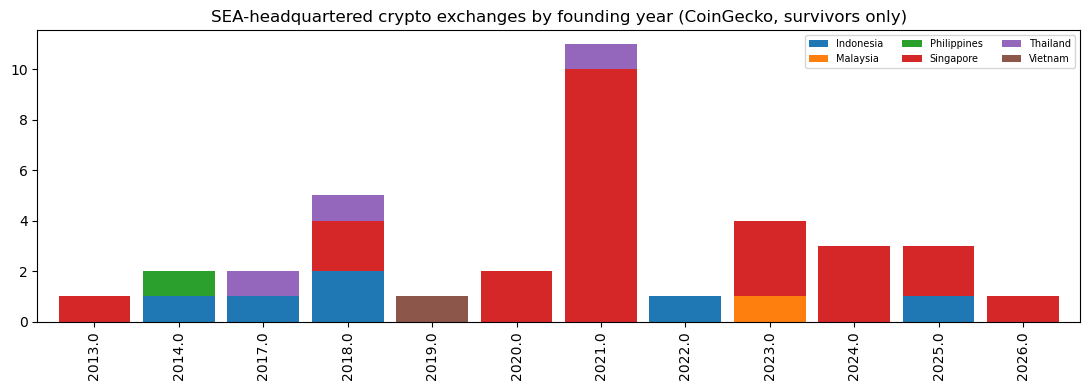

In [11]:
fy = cg_sea.dropna(subset=["year_established"]).groupby(["year_established", "country"]).size().unstack(fill_value=0)
ax = fy.plot(kind="bar", stacked=True, figsize=(11, 4), width=0.85)
ax.set_title("SEA-headquartered crypto exchanges by founding year (CoinGecko, survivors only)")
ax.set_xlabel(""); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "00_crypto_exchanges_founded.png", dpi=150); plt.show()

**Caveat:** CoinGecko lists exchanges that exist today, so exchanges that shut down are missing
(survivorship bias). Firm formation needs a registry-based source to be reliable: Orbis (UCL) by
incorporation year and industry code, or regulators' licence registers.

**Other crypto sources (manual):**
* **Chainalysis Global Crypto Adoption Index:** annual country ranks since 2020 (6 editions). This is too
  short for the 8-year rule on its own.
* **Indonesia Bappebti / OJK:** monthly crypto transaction value and registered customers, roughly 2020 onward.
* **Thailand SEC:** digital-asset trading statistics, roughly 2021 onward.
* **Electric Capital:** developer counts by country, recent years only.

## 7 · Other drivers: COVID restrictions and news attention

In [12]:
ox = fetch.fetch_oxcgrt()
ox["Date"] = pd.to_datetime(ox["Date"].astype(str), format="%Y%m%d", errors="coerce")
print("OxCGRT countries:", sorted(ox.CountryCode.unique()))
print("date range:", ox.Date.min().date(), "→", ox.Date.max().date())
ox.groupby("CountryCode").StringencyIndex_Average.mean().round(1).sort_values()

OxCGRT countries: ['BRN', 'CHN', 'IDN', 'IND', 'KHM', 'LAO', 'MMR', 'MYS', 'PHL', 'SGP', 'THA', 'TLS', 'USA', 'VNM']
date range: 2020-01-01 → 2022-12-31


CountryCode
TLS    36.2
BRN    39.5
THA    43.0
SGP    43.6
KHM    45.1
LAO    46.1
USA    48.4
MYS    49.2
IDN    54.5
VNM    54.7
IND    57.9
PHL    58.5
MMR    63.7
CHN    73.3
Name: StringencyIndex_Average, dtype: float64

In [13]:
g = fetch.fetch_gdelt_timeline('"digital payment" sourcecountry:indonesia', "test_digital_payment_id")
if "timeline" in g:
    tl = pd.DataFrame(g["timeline"][0]["data"])
    tl["date"] = pd.to_datetime(tl["date"], format="%Y%m%dT%H%M%SZ", errors="coerce")
    print(f"GDELT works: {len(tl)} points from {tl.date.min().date()} to {tl.date.max().date()}")
else:
    print("GDELT test failed:", str(g)[:200])

GDELT works: 3531 points from 2017-01-01 to 2026-10-06


## 8 · Go / no-go verdict per sector group

In [14]:
# Fintech: a country passes if EITHER mobile-money OR mobile/internet-banking transaction value has >= 8 years.
value_inds = ["mobile_money_tx_value_pct_gdp", "mobile_internet_banking_tx_value_pct_gdp"]
best_per_country = (fas_cov[fas_cov.indicator.isin(value_inds) & fas_cov.iso3.isin(SEA)]
                    .groupby("iso3").n_years.max().reindex(SEA).fillna(0).astype(int))
fintech_pass = int((best_per_country >= MIN_YEARS).sum())
print("Best fintech-outcome years per country (mobile money OR mobile/internet banking):")
print(best_per_country.rename(index=NAME).to_string())
econsea_years = len(COUNTRY_SECTOR_YEARS)

verdict = pd.DataFrame([
    dict(group="Fintech", best_outcome="IMF FAS digital-payment value (% GDP), best of mobile money / mobile & internet banking",
         countries_with_8yrs=fintech_pass, years_available="2007–2025 (varies)",
         verdict="GO" if fintech_pass >= MIN_COUNTRIES else "NARROW",
         note="Singapore, Brunei and Laos have no usable FAS series; Singapore needs MAS data. Central-bank rail data adds depth for Tier A."),
    dict(group="Digital sectors", best_outcome="e-Conomy SEA GMV (country × sector)",
         countries_with_8yrs=6 if econsea_years >= MIN_YEARS else 0,
         years_available=f"2019–2025 ({econsea_years} yrs), Tier A only",
         verdict="GO" if econsea_years >= MIN_YEARS else "NARROW (1 yr short)",
         note="Transport & food combined before 2021. Options: accept 7 yrs; extend with Euromonitor Passport (UCL)."),
    dict(group="Crypto", best_outcome="Regulator statistics + Chainalysis index",
         countries_with_8yrs=0, years_available="~2019/2020–2025",
         verdict="NARROW",
         note="No 8-year harmonised series exists. Analyse with shorter windows: licensing event studies, firm formation (Orbis)."),
]).set_index("group")
verdict.to_csv(PROC / "p0_verdict.csv")
verdict

Best fintech-outcome years per country (mobile money OR mobile/internet banking):
iso3
Indonesia      19
Malaysia       13
Philippines    15
Singapore       0
Thailand       16
Vietnam        11
Brunei          0
Cambodia       17
Laos            0
Myanmar         7
Timor-Leste     1


,best_outcome,countries_with_8yrs,years_available,verdict,note
group,,,,,
Fintech,"IMF FAS digital-payment value (% GDP), best of...",6,2007–2025 (varies),GO,"Singapore, Brunei and Laos have no usable FAS ..."
Digital sectors,e-Conomy SEA GMV (country × sector),0,"2019–2025 (7 yrs), Tier A only",NARROW (1 yr short),Transport & food combined before 2021. Options...
Crypto,Regulator statistics + Chainalysis index,0,~2019/2020–2025,NARROW,No 8-year harmonised series exists. Analyse wi...
